# Index Insurance for Colombian Farmers: Area-Yield vs Weather-Index vs Machine-Learning Triggers, Basis Risk and Pricing from Municipal Yields, CHIRPS and NASA POWER

A smallholder who loses a harvest to drought or flooding rarely has insurance: assessing losses farm by farm costs more than the premium a small farmer can pay. Index insurance avoids the visit. It pays when a measured index (rainfall at the farm's location, or the average yield of the area) falls below a threshold, so claims can be settled quickly and cheaply. Its weakness is the same as for any parametric cover: the index may not move with the farmer's loss. This notebook measures that gap for five staple crops in Colombia, with eighteen years of municipal production data and forty years of satellite rainfall.

**What it does.**

1. It builds a panel of production per sown hectare for maize, rice, beans, potatoes and coffee in about a thousand municipalities (2007–2024, Colombia's Municipal Agricultural Evaluations), detrends it and turns shortfalls into the payout of an insurance cover at 80% of expected production.
2. It attaches season-level weather to every municipality: CHIRPS rainfall at 5 km, NASA POWER temperature and root-zone soil moisture, and the El Niño index.
3. It checks where the weather signal is (municipality or department) and compares three triggers for a department-level cover: a classic rainfall deficit-and-excess contract, a soil-moisture contract and a machine-learning weather index (LightGBM and a Keras network), fitted on 2007–2016 and tested on 2017–2024. It then measures how much of each municipality's own loss the department covers, including a department area-yield cover, would reach.
4. It prices the weather-based covers over 1991–2024 and shows how the expected payout changes between El Niño, neutral and La Niña seasons.

**Data.** Evaluaciones Agropecuarias Municipales (Ministry of Agriculture, via datos.gov.co), DIVIPOLA municipal coordinates (DANE), CHIRPS monthly rainfall (Climate Hazards Center, UC Santa Barbara), NASA POWER monthly temperature and soil moisture, the Oceanic Niño Index (NOAA Climate Prediction Center) and FAOSTAT national yields for a cross-check.

**Methods.** Robust (Theil–Sen) detrending of log production per sown hectare, season-specific rainfall, heat and soil-moisture anomalies, aggregation to departments with sown-area weights, fixed-scale rainfall and soil-moisture contracts, isotonic calibration of the machine-learning index, monotone-constrained gradient boosting and a neural network with grouped validation and an out-of-time test, basis-risk measures and burning-cost pricing with ENSO conditioning.

**Key output.** How much of the loss is explained by weather at all, at municipal and department level; how often and how much each trigger pays when production falls, by crop, in and out of sample; how much a department cover reaches the farm; and what a cover costs per year, in average, El Niño and La Niña seasons.

## 1. Index insurance and basis risk

**Indemnity, area-yield and weather index.** Traditional crop insurance pays the farmer's assessed loss. **Area-yield** insurance pays when the average yield of an area (a municipality or a department) falls below a guaranteed share of its expected level; it needs no farm visit but waits for the yield statistics. **Weather-index** insurance pays on rainfall or temperature measured by satellites or stations, which is available within days and cannot be manipulated by either party.

**The cover.** For each municipality, crop and season, let $r$ be production per sown hectare divided by its expected (trend) value. A cover at 80% pays the shortfall below 80% of expected production, as a share of the insured value:

$$I = \frac{\max(0.8 - r,\ 0)}{0.8}.$$

Using production per *sown* hectare, rather than yield per *harvested* hectare, matters: when a flood destroys a field, the area is never harvested and a yield-only measure misses the loss.

**Basis risk** is the gap between what an index pays and $I$. As in sovereign parametric covers, it has two sides: missed losses (the farmer lost but the index did not trigger) and false alarms (the index paid without a loss). For a farmer, a missed payout in a bad year is the costly side. Insurance that fails exactly when it is needed destroys trust in the product.

**ENSO.** Colombia's rainfall is strongly modulated by the El Niño–Southern Oscillation: El Niño tends to bring drought to the Andean and Caribbean regions, and La Niña heavy rain and flooding (2010–2011 was the worst on record). A cover priced on average weather may be cheap or expensive depending on the phase of ENSO when it is sold.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import gzip
import unicodedata
import keras
import lightgbm as lgb
import tifffile
import torch
from scipy import stats
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2010
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

FIRST_YEAR, LAST_YEAR, SPLIT_YEAR = 2007, 2024, 2016
CLIM_START, CLIM_END = 1991, 2020  # climatology for anomalies
WEATHER_START = 1991  # first season priced
COVERAGE = 0.80
MIN_YEARS = 12  # series kept if >= 12 seasons
CROPS = {
    "MAIZ": "maize",
    "ARROZ": "rice",
    "FRIJOL": "beans",
    "PAPA": "potatoes",
    "CAFE": "coffee",
}
SEASON_MONTHS = {
    "A": [(0, m) for m in range(3, 9)],
    "B": [(0, m) for m in range(9, 13)] + [(1, 1), (1, 2)],
    "Y": [(0, m) for m in range(1, 13)],
}
LOADING = 1.5  # premium = 1.5 x burning cost
UA = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
        "Chrome/130.0 Safari/537.36"
    )
}

print(
    f"keras {keras.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

keras 3.15.1 · lightgbm 4.7.0 · run on 2026-10-28


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Production data: the Municipal Agricultural Evaluations

Colombia's Ministry of Agriculture publishes, for every municipality, crop and season, the area sown, the area harvested and the production. Two releases cover 2006–2018 and 2019 onwards. Annual crops have two seasons (A, planted early in the year, and B, planted in the second half); coffee is reported by year.

Two data-quality points shape the analysis:

- **Stale yields.** A sizeable share of municipal yields is identical to the previous year's, a sign that the estimate was carried forward rather than measured. These records still carry information through the areas, but they flatten yield variability and therefore understate risk.
- **Unharvested area.** The gap between sown and harvested area is where floods and droughts show up most clearly. It is kept by measuring production per sown hectare.

In [3]:
SODA = "https://www.datos.gov.co/resource/{}.json"


def soda(resource, where, select):
    out, offset = [], 0
    while True:
        r = requests.get(
            SODA.format(resource),
            timeout=300,
            params={
                "$where": where,
                "$select": select,
                "$limit": 50000,
                "$offset": offset,
            },
        )
        r.raise_for_status()
        batch = r.json()
        out += batch
        offset += len(batch)
        if len(batch) < 50000:
            return pd.DataFrame(out)


def fetch_eva():
    old = soda(
        "2pnw-mmge",
        "cultivo in ('MAIZ','ARROZ','PAPA','FRIJOL','CAFE')",
        "c_d_mun as mun, cultivo, a_o as year, periodo, "
        "rea_sembrada_ha as sown, rea_cosechada_ha as harv, "
        "producci_n_t as prod",
    )
    new = soda(
        "uejq-wxrr",
        "cultivo in ('Maíz','Arroz','Papa','Frijol','Café')",
        "c_digo_dane_municipio as mun, cultivo, a_o as year, "
        "periodo, rea_sembrada as sown, rea_cosechada as harv, "
        "producci_n as prod",
    )
    return pd.concat([old, new], ignore_index=True).astype(str)


def fetch_divipola():
    return soda(
        "gdxc-w37w", "1=1", "cod_mpio, nom_mpio, dpto, latitud, longitud"
    )


plain = (
    lambda s: unicodedata.normalize("NFKD", s)
    .encode("ascii", "ignore")
    .decode()
    .upper()
)
RAW = cached(
    "eva_maize_rice_beans_potato_coffee", fetch_eva, max_age_hours=24 * 30
)
DIV = cached("divipola", fetch_divipola, max_age_hours=24 * 90)
DIV = pd.DataFrame({
    "mun": DIV["cod_mpio"].str.zfill(5),
    "name": DIV["nom_mpio"],
    "dept": DIV["dpto"],
    "lat": DIV["latitud"].str.replace(",", ".").astype(float),
    "lon": DIV["longitud"].str.replace(",", ".").astype(float),
})

eva = RAW.copy()
eva["crop"] = eva["cultivo"].map(plain).map(CROPS)
for c in ["sown", "harv", "prod", "year"]:
    eva[c] = pd.to_numeric(eva[c], errors="coerce")
last = eva["periodo"].str[-1]
eva["season"] = last.where(last.isin(["A", "B"]), "Y")
eva["mun"] = eva["mun"].str.zfill(5)
PANEL = eva.groupby(["mun", "crop", "season", "year"], as_index=False)[
    ["sown", "harv", "prod"]
].sum()
PANEL = PANEL[
    PANEL["year"].between(FIRST_YEAR, LAST_YEAR)
    & (PANEL["sown"] > 0)
    & (PANEL["harv"] > 0)
    & (PANEL["prod"] > 0)
]
PANEL["series"] = PANEL["mun"] + "_" + PANEL["crop"] + "_" + PANEL["season"]
n_years = PANEL.groupby("series")["year"].transform("nunique")
PANEL = PANEL[n_years >= MIN_YEARS].merge(DIV, on="mun", how="inner")
PANEL = PANEL.sort_values(["series", "year"]).reset_index(drop=True)
PANEL["yield"] = PANEL["prod"] / PANEL["harv"]
PANEL["pps"] = PANEL["prod"] / PANEL["sown"]  # per sown hectare
PANEL["unharvested"] = 1 - PANEL["harv"] / PANEL["sown"]
PANEL["stale"] = PANEL.groupby("series")["yield"].diff().abs() < 1e-9

QUALITY = PANEL.groupby("crop").agg(
    municipalities=("mun", "nunique"),
    series=("series", "nunique"),
    seasons=("year", "size"),
    stale_yields=("stale", "mean"),
    unharvested=("unharvested", "mean"),
)
print(
    f"{PANEL['mun'].nunique()} municipalities, "
    f"{PANEL['series'].nunique()} crop-season series, "
    f"{len(PANEL):,} observations {FIRST_YEAR}–{LAST_YEAR}"
)
QUALITY.style.format({"stale_yields": "{:.0%}", "unharvested": "{:.1%}"})

1087 municipalities, 4428 crop-season series, 73,092 observations 2007–2024


,municipalities,series,seasons,stale_yields,unharvested
crop,,,,,
beans,626,1120,18092,26%,4.2%
coffee,603,603,10667,3%,15.7%
maize,979,1752,28630,22%,-2.7%
potatoes,258,476,7924,25%,3.6%
rice,269,477,7779,16%,-7.1%


**Detrending.** Productivity changes over time (new seeds, irrigation, shifts in where a crop is grown), so a shortfall is measured against each series' own trend. The trend is a Theil–Sen line on log production per sown hectare, which is not pulled by the bad years themselves. The ratio $r$ of actual to trend production, and the payout $I$ of the 80% cover, follow.

In [4]:
log_pps = np.log(PANEL["pps"])
trend = np.empty(len(PANEL))
for key, idx in PANEL.groupby("series").indices.items():
    yrs = PANEL["year"].to_numpy()[idx]
    slope, icpt, _, _ = stats.theilslopes(log_pps.to_numpy()[idx], yrs)
    trend[idx] = icpt + slope * yrs
PANEL["ratio"] = np.exp(log_pps - trend)
PANEL["log_ratio"] = log_pps - trend


def payout_from_ratio(r):
    return np.clip(COVERAGE - np.asarray(r), 0, None) / COVERAGE


PANEL["ideal"] = payout_from_ratio(PANEL["ratio"])
LOSS_SUMMARY = PANEL.groupby(["crop", "season"]).agg(
    observations=("ratio", "size"),
    loss_frequency=("ideal", lambda s: (s > 0).mean()),
    mean_payout=("ideal", "mean"),
    worst_year=(
        "year",
        lambda s: PANEL.loc[s.index].groupby("year")["ideal"].mean().idxmax(),
    ),
)
LOSS_SUMMARY.style.format(
    {"loss_frequency": "{:.0%}", "mean_payout": "{:.1%}"}
)

## 4. Weather: CHIRPS rainfall, NASA POWER heat and soil moisture, and ENSO

- **CHIRPS** blends satellite infrared estimates with station data into monthly rainfall at 0.05° (about 5 km) since 1981. The notebook downloads each monthly global file once, keeps only the Colombian window and averages the 3 × 3 pixels around each municipal seat.
- **NASA POWER** provides monthly maximum temperature, root-zone soil wetness and (for comparison) rainfall on a 0.5° grid from the MERRA-2 reanalysis.
- **The Oceanic Niño Index** (three-month mean sea-surface temperature anomaly in the Niño 3.4 region) measures the phase of ENSO.

For each season, rainfall is expressed against the municipality's 1991–2020 climatology for the same months. Features are the season total, the driest and wettest months (as ratios to normal), the number of months below half or above one and a half times normal, the maximum-temperature and soil-wetness anomalies, and the mean ONI.

In [5]:
CHIRPS_URL = (
    "https://data.chc.ucsb.edu/products/CHIRPS-2.0/global_monthly/"
    "tifs/chirps-v2.0.{y}.{m:02d}.tif.gz"
)
WIN = dict(lat0=-4.5, lat1=13.0, lon0=-79.5, lon1=-66.5)
R0, R1 = int((50 - WIN["lat1"]) / 0.05), int((50 - WIN["lat0"]) / 0.05)
C0, C1 = int((WIN["lon0"] + 180) / 0.05), int((WIN["lon1"] + 180) / 0.05)
CHIRPS_DIR = DATA_DIR / "chirps"
CHIRPS_DIR.mkdir(exist_ok=True)


def chirps_month(y, m):
    """Colombian window of one CHIRPS month (mm), cached as .npy."""
    path = CHIRPS_DIR / f"{y}{m:02d}.npy"
    if path.exists():
        return np.load(path)
    for attempt in range(6):
        r = requests.get(CHIRPS_URL.format(y=y, m=m), headers=UA, timeout=120)
        if r.status_code == 200 and r.content[:2] == b"\x1f\x8b":
            a = tifffile.imread(io.BytesIO(gzip.decompress(r.content)))
            a = a[R0:R1, C0:C1].astype(np.float32)
            a[a < 0] = np.nan
            np.save(path, a)
            return a
        if r.status_code == 404:
            return None
        time.sleep(10 * (attempt + 1))
    return None


months = [
    (y, m) for y in range(WEATHER_START, LAST_YEAR + 2) for m in range(1, 13)
]
t0_ = time.time()
CHIRPS = {
    f"{y}{m:02d}": a
    for y, m in months
    if (a := chirps_month(y, m)) is not None
}
MUNS = DIV.set_index("mun").loc[sorted(PANEL["mun"].unique())]
ri = np.clip(((50 - MUNS["lat"]) / 0.05).astype(int) - R0, 1, R1 - R0 - 2)
ci = np.clip(((MUNS["lon"] + 180) / 0.05).astype(int) - C0, 1, C1 - C0 - 2)
RAIN = pd.DataFrame(
    {
        k: np.nanmean(
            np.stack([
                a[ri.to_numpy() + dr, ci.to_numpy() + dc]
                for dr in (-1, 0, 1)
                for dc in (-1, 0, 1)
            ]),
            axis=0,
        )
        for k, a in sorted(CHIRPS.items())
    },
    index=MUNS.index,
)
print(
    f"CHIRPS: {RAIN.shape[1]} months ({min(CHIRPS)}–{max(CHIRPS)}) at "
    f"{len(RAIN)} municipalities, {time.time() - t0_:.0f} s"
)

CHIRPS: 420 months (199101–202512) at 1087 municipalities, 0 s


In [6]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/monthly/regional"
TILES = [
    (-4.5, 4.5, -79.5, -73),
    (-4.5, 4.5, -73, -66.5),
    (4.5, 13, -79.5, -73),
    (4.5, 13, -73, -66.5),
]


def fetch_power():
    rows = []
    for p in ["T2M_MAX", "GWETROOT", "PRECTOTCORR"]:
        for la0, la1, lo0, lo1 in TILES:
            r = requests.get(
                POWER_URL,
                timeout=600,
                params={
                    "parameters": p,
                    "community": "AG",
                    "latitude-min": la0,
                    "latitude-max": la1,
                    "longitude-min": lo0,
                    "longitude-max": lo1,
                    "start": WEATHER_START,
                    "end": LAST_YEAR + 1,
                    "format": "JSON",
                },
            )
            r.raise_for_status()
            for f in r.json()["features"]:
                lon, lat = f["geometry"]["coordinates"][:2]
                rows += [
                    (lat, lon, p, k, v)
                    for k, v in f["properties"]["parameter"][p].items()
                    if k[-2:] != "13"
                ]
    return pd.DataFrame(
        rows, columns=["lat", "lon", "param", "ym", "value"]
    ).drop_duplicates()


def fetch_oni():
    txt = requests.get(
        "https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt", timeout=60
    ).text.split("\n")[1:]
    seas = [
        "DJF",
        "JFM",
        "FMA",
        "MAM",
        "AMJ",
        "MJJ",
        "JJA",
        "JAS",
        "ASO",
        "SON",
        "OND",
        "NDJ",
    ]
    rows = [l.split() for l in txt if l.strip()]
    return pd.DataFrame({
        "ym": [f"{r[1]}{seas.index(r[0]) + 1:02d}" for r in rows],
        "oni": [float(r[3]) for r in rows],
    })


POWER = cached("nasa_power_monthly", fetch_power, max_age_hours=24 * 30)
POWER = POWER[POWER["value"] > -900]
ONI = cached("oni", fetch_oni, max_age_hours=24 * 7).set_index("ym")["oni"]
grid = POWER[["lat", "lon"]].drop_duplicates().to_numpy()
near = (
    (MUNS["lat"].to_numpy()[:, None] - grid[:, 0]) ** 2
    + (MUNS["lon"].to_numpy()[:, None] - grid[:, 1]) ** 2
).argmin(1)
cell = pd.MultiIndex.from_arrays([grid[near, 0], grid[near, 1]])
PW = {
    p: (
        POWER[POWER["param"] == p]
        .pivot_table(index=["lat", "lon"], columns="ym", values="value")
        .reindex(cell)
        .set_axis(MUNS.index)
    )
    for p in ["T2M_MAX", "GWETROOT", "PRECTOTCORR"]
}
print(
    f"NASA POWER: {len(grid)} grid cells; ONI to {ONI.index.max()} "
    f"(latest {ONI.iloc[-1]:+.2f})"
)

NASA POWER: 756 grid cells; ONI to 202608 (latest +2.16)


In [7]:
def season_cols(year, season, columns):
    cols = [f"{year + dy}{m:02d}" for dy, m in SEASON_MONTHS[season]]
    return cols if all(c in columns for c in cols) else None


def climatology(frame, season, how):
    vals = []
    for y in range(CLIM_START, CLIM_END + 1):
        cols = season_cols(y, season, frame.columns)
        if cols:
            vals.append(getattr(frame[cols], how)(axis=1))
    return pd.concat(vals, axis=1).mean(axis=1)


def month_normals(frame):
    norm = {}
    for m in range(1, 13):
        cols = [
            f"{y}{m:02d}"
            for y in range(CLIM_START, CLIM_END + 1)
            if f"{y}{m:02d}" in frame.columns
        ]
        norm[m] = frame[cols].mean(axis=1)
    return pd.DataFrame(norm)


RAIN_NORM = month_normals(RAIN)
POWER_RAIN_NORM = month_normals(PW["PRECTOTCORR"])
T_NORM = month_normals(PW["T2M_MAX"])
W_NORM = month_normals(PW["GWETROOT"])


def weather_features(years):
    out = []
    for season in ["A", "B", "Y"]:
        for y in years:
            cols = season_cols(y, season, RAIN.columns)
            pcols = season_cols(y, season, PW["T2M_MAX"].columns)
            if cols is None or pcols is None:
                continue
            ms = [int(c[4:]) for c in cols]
            ratio = RAIN[cols].to_numpy() / RAIN_NORM[ms].to_numpy()
            p_ratio = (
                PW["PRECTOTCORR"][pcols].to_numpy()
                / POWER_RAIN_NORM[ms].to_numpy()
            )
            t_an = PW["T2M_MAX"][pcols].to_numpy() - T_NORM[ms].to_numpy()
            w_an = PW["GWETROOT"][pcols].to_numpy() - W_NORM[ms].to_numpy()
            tot = (
                RAIN[cols].sum(axis=1).to_numpy()
                / RAIN_NORM[ms].sum(axis=1).to_numpy()
            )
            out.append(
                pd.DataFrame({
                    "mun": RAIN.index,
                    "season": season,
                    "year": y,
                    "rain_total": tot,
                    "rain_min_month": np.nanmin(ratio, axis=1),
                    "rain_max_month": np.nanmax(ratio, axis=1),
                    "dry_months": (ratio < 0.5).sum(axis=1),
                    "wet_months": (ratio > 1.5).sum(axis=1),
                    "power_rain_total": (
                        PW["PRECTOTCORR"][pcols].sum(axis=1).to_numpy()
                        / POWER_RAIN_NORM[ms].sum(axis=1).to_numpy()
                    ),
                    "power_rain_min_month": np.nanmin(p_ratio, axis=1),
                    "tmax_anom": t_an.mean(axis=1),
                    "tmax_anom_max": t_an.max(axis=1),
                    "soil_wet_anom": w_an.mean(axis=1),
                    "soil_wet_anom_min": w_an.min(axis=1),
                    "oni": ONI.reindex(cols).mean(),
                })
            )
    w = pd.concat(out, ignore_index=True)
    w["deficit"] = np.clip(1 - w["rain_total"], 0, None)
    w["excess"] = np.clip(w["rain_total"] - 1, 0, None)
    return w


WEATHER = weather_features(range(WEATHER_START, LAST_YEAR + 1))
DATA = PANEL.merge(WEATHER, on=["mun", "season", "year"], how="inner")
print(
    f"{len(WEATHER):,} municipality-seasons of weather "
    f"{WEATHER_START}–{LAST_YEAR}; {len(DATA):,} matched to production"
)

110,874 municipality-seasons of weather 1991–2024; 73,092 matched to production


## 5. Where is the weather signal?

The first question is whether weather explains production at all in this data. The table compares the rank correlation between the production ratio and each weather feature at two levels: the municipality, and the department (production and sown area added up over its municipalities, weather averaged with sown-area weights). The second table follows maize in the Caribbean departments year by year, where the 2015–2016 El Niño drought and the 2010–2011 La Niña floods are well documented.

In [8]:
DEPT_KEYS = ["dept", "crop", "season", "year"]
W_COLS = [
    "rain_total",
    "rain_min_month",
    "rain_max_month",
    "dry_months",
    "wet_months",
    "power_rain_total",
    "tmax_anom",
    "tmax_anom_max",
    "soil_wet_anom",
    "soil_wet_anom_min",
    "oni",
    "deficit",
    "excess",
]


def to_department(d):
    w = d["sown"].to_numpy()
    out = d[DEPT_KEYS].copy()
    for c in W_COLS:
        out[c] = d[c].to_numpy() * w
    out["prod"], out["sown"], out["w"] = d["prod"], d["sown"], w
    out["lat_w"] = d["lat"].to_numpy() * w
    g = out.groupby(DEPT_KEYS, as_index=False).sum(numeric_only=True)
    for c in W_COLS + ["lat_w"]:
        g[c] = g[c] / g["w"]
    g["n_mun"] = d.groupby(DEPT_KEYS)["mun"].nunique().to_numpy()
    return g.rename(columns={"lat_w": "lat"})


DEP = to_department(DATA)
DEP = DEP[DEP["n_mun"] >= 3].copy()
DEP["unit"] = DEP["dept"] + "_" + DEP["crop"] + "_" + DEP["season"]
DEP = DEP[DEP.groupby("unit")["year"].transform("nunique") >= MIN_YEARS]
DEP = DEP.sort_values(["unit", "year"]).reset_index(drop=True)
lp = np.log(DEP["prod"] / DEP["sown"])
tr_ = np.empty(len(DEP))
for key, idx in DEP.groupby("unit").indices.items():
    yrs = DEP["year"].to_numpy()[idx]
    sl, ic, _, _ = stats.theilslopes(lp.to_numpy()[idx], yrs)
    tr_[idx] = ic + sl * yrs
DEP["log_ratio"] = lp - tr_
DEP["ratio"] = np.exp(DEP["log_ratio"])
DEP["ideal"] = payout_from_ratio(DEP["ratio"])
DEP["trend_level"] = tr_


def corr_table(d, feats):
    return pd.DataFrame(
        {
            crop: [
                stats.spearmanr(g[f], g["log_ratio"], nan_policy="omit")[0]
                for f in feats
            ]
            for crop, g in d.groupby("crop")
        },
        index=feats,
    )


FEATS_SHOW = [
    "rain_total",
    "rain_min_month",
    "power_rain_total",
    "tmax_anom",
    "soil_wet_anom",
    "oni",
]
SIGNAL = pd.concat(
    {
        "municipality": corr_table(DATA, FEATS_SHOW),
        "department": corr_table(DEP, FEATS_SHOW),
    },
    axis=1,
)
CARIBBEAN = {
    plain(x)
    for x in [
        "ATLÁNTICO",
        "BOLÍVAR",
        "CESAR",
        "CÓRDOBA",
        "LA GUAJIRA",
        "MAGDALENA",
        "SUCRE",
    ]
}
car = DEP[(DEP["crop"] == "maize") & DEP["dept"].map(plain).isin(CARIBBEAN)]
CARIBBEAN_MAIZE = car.groupby("year").agg(
    production_vs_trend=("log_ratio", lambda s: np.expm1(s.mean())),
    rainfall_vs_normal=("rain_total", "mean"),
    oni=("oni", "mean"),
)
print(
    f"{DEP['unit'].nunique()} department-crop-season units, "
    f"{len(DEP):,} observations"
)
display(
    SIGNAL.style.format("{:+.2f}").background_gradient(
        cmap="RdBu", vmin=-0.4, vmax=0.4
    )
)
CARIBBEAN_MAIZE.style.format({
    "production_vs_trend": "{:+.0%}",
    "rainfall_vs_normal": "{:.0%}",
    "oni": "{:+.2f}",
})

171 department-crop-season units, 2,983 observations


,production_vs_trend,rainfall_vs_normal,oni
year,,,
2007,+33%,118%,-0.96
2008,+28%,112%,-0.67
2009,-4%,84%,+0.63
2010,-17%,151%,-0.85
2011,-0%,132%,-0.68
2012,+5%,99%,-0.00
2013,+8%,98%,-0.25
2014,-19%,89%,+0.38
2015,-33%,69%,+1.75


## 6. Three weather triggers for a department-level cover

The insured unit is a department's production of one crop in one season, with the 80% cover of section 1. Three weather-based triggers compete, all fitted on 2007–2016 and tested on 2017–2024:

- **Rainfall contract.** The classic design pays linearly when season rainfall falls below 75% of normal (full payout at 40%) or rises above 140% (full payout at 200%). The two scales are fixed in advance, as in a real term sheet; a single factor per crop then makes the contract actuarially fair on the training years.
- **Soil-moisture contract.** The same design on the NASA POWER root-zone wetness anomaly (dry: below −0.05, full at −0.20; wet: above +0.08, full at +0.20), which integrates rainfall, temperature and evaporation.
- **Machine-learning weather index.** LightGBM and a Keras network predict the department's log production ratio from all the weather features, the crop, the season, the region and the trend level. The boosting model is constrained so that a larger deficit, a larger excess, more dry or wet months, more heat or drier soil never raise the predicted production. The out-of-fold predictions (grouped by year) are turned into payouts with an isotonic regression on the ideal payout, so the index pays the expected loss for each predicted value.

Payouts below 2% of the insured value are not made.

In [9]:
def ramp(x, start, full):
    return np.clip((x - start) / (full - start), 0, 1)


def rain_raw(t):
    return np.maximum(
        ramp(-t["rain_total"], -0.75, -0.40), ramp(t["rain_total"], 1.40, 2.00)
    ).to_numpy()


def soil_raw(t):
    return np.maximum(
        ramp(-t["soil_wet_anom"], 0.05, 0.20),
        ramp(t["soil_wet_anom"], 0.08, 0.20),
    ).to_numpy()


D_TRAIN = DEP[DEP["year"] <= SPLIT_YEAR].copy()
D_TEST = DEP[DEP["year"] > SPLIT_YEAR].copy()
SCALE = {}
for name, f in [
    ("rainfall contract", rain_raw),
    ("soil-moisture contract", soil_raw),
]:
    for crop, g in D_TRAIN.groupby("crop"):
        raw = f(g)
        SCALE[name, crop] = g["ideal"].sum() / max(raw.sum(), 1e-9)

WFEATS = [
    "deficit",
    "excess",
    "rain_min_month",
    "rain_max_month",
    "dry_months",
    "wet_months",
    "tmax_anom",
    "tmax_anom_max",
    "soil_wet_anom",
    "soil_wet_anom_min",
    "oni",
]
SIGN = {
    "deficit": -1,
    "excess": -1,
    "rain_min_month": 1,
    "rain_max_month": -1,
    "dry_months": -1,
    "wet_months": -1,
    "tmax_anom": -1,
    "tmax_anom_max": -1,
    "soil_wet_anom": 0,
    "soil_wet_anom_min": 1,
    "oni": 0,
}
CROP_LIST = sorted(CROPS.values())
REGIONS = {
    "caribbean": CARIBBEAN,
    "orinoquia_amazon": {
        plain(x)
        for x in [
            "META",
            "CASANARE",
            "ARAUCA",
            "VICHADA",
            "GUAVIARE",
            "CAQUETÁ",
            "PUTUMAYO",
            "AMAZONAS",
            "GUAINÍA",
            "VAUPÉS",
        ]
    },
}


def region(dept):
    d = plain(dept)
    return next((k for k, v in REGIONS.items() if d in v), "andean_pacific")


def design(t):
    x = t[WFEATS].astype(float).copy()
    for c in CROP_LIST:
        x[f"crop_{c}"] = (t["crop"] == c).astype(float)
    for s in ["A", "B", "Y"]:
        x[f"season_{s}"] = (t["season"] == s).astype(float)
    reg = t["dept"].map(region)
    for r in ["caribbean", "orinoquia_amazon", "andean_pacific"]:
        x[f"region_{r}"] = (reg == r).astype(float)
    x["trend_level"] = t["trend_level"].to_numpy()
    x["lat"] = t["lat"].to_numpy()
    return x


cols = design(D_TRAIN.head()).columns
MONO = [SIGN.get(c, 0) for c in cols]
LGB_PARAMS = dict(
    objective="huber",
    alpha=0.3,
    metric="l2",
    learning_rate=0.03,
    num_leaves=7,
    min_data_in_leaf=30,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=5.0,
    monotone_constraints=MONO,
    verbose=-1,
    seed=SEED,
)
N_ROUNDS = 300


def keras_model(n_in):
    model = keras.Sequential([
        keras.layers.Input((n_in,)),
        keras.layers.Dense(32, "relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(16, "relu"),
        keras.layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="huber")
    return model


def fit_ml(x, y):
    booster = lgb.train(LGB_PARAMS, lgb.Dataset(x, y), N_ROUNDS)
    scaler = StandardScaler().fit(x)
    net = keras_model(x.shape[1])
    net.fit(
        scaler.transform(x),
        y,
        epochs=200,
        batch_size=64,
        verbose=0,
        validation_split=0.15,
        callbacks=[
            keras.callbacks.EarlyStopping(
                patience=20, restore_best_weights=True
            )
        ],
    )
    return booster, scaler, net


def predict_ml(models, x, w):
    booster, scaler, net = models
    p_gb = booster.predict(x)
    p_nn = net.predict(scaler.transform(x), verbose=0, batch_size=8192)[:, 0]
    return {
        "LightGBM": p_gb,
        "Keras": p_nn,
        "ensemble": w * p_gb + (1 - w) * p_nn,
    }


X_TR, Y_TR = design(D_TRAIN), D_TRAIN["log_ratio"].to_numpy()
OOF = {k: np.zeros(len(D_TRAIN)) for k in ["LightGBM", "Keras"]}
for a, b in GroupKFold(5).split(X_TR, Y_TR, D_TRAIN["year"]):
    m = fit_ml(X_TR.iloc[a], Y_TR[a])
    for k, v in predict_ml(m, X_TR.iloc[b], 0.5).items():
        if k in OOF:
            OOF[k][b] = v
W_GB = min(
    np.linspace(0, 1, 21),
    key=lambda w: np.mean(
        (Y_TR - w * OOF["LightGBM"] - (1 - w) * OOF["Keras"]) ** 2
    ),
)
OOF["ensemble"] = W_GB * OOF["LightGBM"] + (1 - W_GB) * OOF["Keras"]
ML = fit_ml(X_TR, Y_TR)
PRED_TE = predict_ml(ML, design(D_TEST), W_GB)
ML_MAP = IsotonicRegression(
    y_min=0, y_max=1, increasing=False, out_of_bounds="clip"
).fit(OOF["ensemble"], D_TRAIN["ideal"])
D_TRAIN["ml"] = OOF["ensemble"]
D_TEST["ml"] = PRED_TE["ensemble"]


def r2(y, p):
    return 1 - np.mean((y - p) ** 2) / np.var(y)


Y_TE = D_TEST["log_ratio"].to_numpy()
ML_SCORES = pd.DataFrame({
    "R² training (out of fold)": {k: r2(Y_TR, v) for k, v in OOF.items()},
    "R² test 2017–2024": {k: r2(Y_TE, v) for k, v in PRED_TE.items()},
    "rank corr. test": {
        k: stats.spearmanr(Y_TE, v)[0] for k, v in PRED_TE.items()
    },
})
imp = pd.Series(ML[0].feature_importance("gain"), index=X_TR.columns)
print(
    f"Blend weight on LightGBM {W_GB:.2f}. Largest gains: "
    + ", ".join(imp.sort_values(ascending=False).head(6).index)
)
ML_SCORES.style.format("{:.3f}")

Blend weight on LightGBM 0.55. Largest gains: oni, lat, soil_wet_anom, trend_level, deficit, rain_max_month


,R² training (out of fold),R² test 2017–2024,rank corr. test
LightGBM,0.015,-0.058,0.076
Keras,0.005,-0.082,0.032
ensemble,0.053,-0.054,0.060


In [10]:
TRIGGERS = ["rainfall contract", "soil-moisture contract", "ML weather index"]


def payouts(t):
    rain = np.array([SCALE["rainfall contract", c] for c in t["crop"]])
    soil = np.array([SCALE["soil-moisture contract", c] for c in t["crop"]])
    out = {
        "rainfall contract": np.clip(rain * rain_raw(t), 0, 1),
        "soil-moisture contract": np.clip(soil * soil_raw(t), 0, 1),
        "ML weather index": ML_MAP.predict(t["ml"].to_numpy()),
    }
    return {k: np.where(v < 0.02, 0.0, v) for k, v in out.items()}


def basis_risk(t, ideal=None):
    ideal = t["ideal"].to_numpy() if ideal is None else ideal
    need = ideal > 0
    rows = {}
    for name, p in payouts(t).items():
        rows[name] = {
            "loss events": int(need.sum()),
            "covered share of ideal payouts": (
                np.minimum(p, ideal).sum() / ideal.sum()
            ),
            "missed loss events": np.mean(p[need] == 0),
            "false alarms (share of money)": (
                p[~need].sum() / max(p.sum(), 1e-12)
            ),
            "abs error / ideal payouts": np.abs(p - ideal).sum() / ideal.sum(),
            "paid / ideal payouts": p.sum() / ideal.sum(),
            "rank corr. with ideal": stats.spearmanr(p, ideal)[0],
        }
    return pd.DataFrame(rows).T


BASIS = pd.concat({
    "training 2007–2016": basis_risk(D_TRAIN),
    "test 2017–2024": basis_risk(D_TEST),
})
BASIS_CROP = pd.concat(
    {
        crop: basis_risk(g)["covered share of ideal payouts"]
        for crop, g in D_TEST.groupby("crop")
    },
    axis=1,
)
pct = [
    "covered share of ideal payouts",
    "missed loss events",
    "false alarms (share of money)",
    "abs error / ideal payouts",
    "paid / ideal payouts",
]
display(
    BASIS.style.format(
        {c: "{:.0%}" for c in pct} | {"rank corr. with ideal": "{:+.2f}"}
    )
)
BASIS_CROP.style.format("{:.0%}")

,beans,coffee,maize,potatoes,rice
rainfall contract,3%,0%,3%,0%,2%
soil-moisture contract,3%,0%,10%,0%,5%
ML weather index,1%,0%,1%,0%,2%


## 7. From the department to the farm

A department-level cover pays every municipality of the department the same. How much of each municipality's own shortfall does it cover? The table applies the department triggers, and the department's own area-yield cover (which is perfect at department level), to the municipal payouts of the test years.

In [11]:
key_cols = ["dept", "crop", "season", "year"]
mun_test = DATA[DATA["year"] > SPLIT_YEAR].merge(
    D_TEST[key_cols + ["ml", "ideal"]].rename(columns={"ideal": "dep_ideal"}),
    on=key_cols,
    how="inner",
)
dep_pay = payouts(D_TEST)
lookup = D_TEST[key_cols].assign(**{k: v for k, v in dep_pay.items()})
mun_test = mun_test.merge(lookup, on=key_cols, how="left")
ideal_m = mun_test["ideal"].to_numpy()
need_m = ideal_m > 0
rows = {}
for name in TRIGGERS + ["dep_ideal"]:
    p = mun_test[name].to_numpy()
    label = "department area-yield" if name == "dep_ideal" else name
    rows[label] = {
        "covered share of municipal ideal payouts": (
            np.minimum(p, ideal_m).sum() / ideal_m.sum()
        ),
        "missed municipal loss events": np.mean(p[need_m] == 0),
        "false alarms (share of money)": (
            p[~need_m].sum() / max(p.sum(), 1e-12)
        ),
    }
FARM = pd.DataFrame(rows).T
within = mun_test.groupby(key_cols)["ideal"].agg(["mean", "std"])
print(
    "Average within-department dispersion of municipal payouts "
    f"(std / mean): {(within['std'] / within['mean']).median():.1f}"
)
FARM.style.format("{:.0%}")

Average within-department dispersion of municipal payouts (std / mean): 2.5


,covered share of municipal ideal payouts,missed municipal loss events,false alarms (share of money)
rainfall contract,1%,96%,78%
soil-moisture contract,3%,84%,79%
ML weather index,1%,91%,85%
department area-yield,6%,87%,53%


## 8. Pricing over 34 years of weather, and ENSO

A weather contract can be priced on the long weather record. Each department cover is applied to every season from 1991 to 2024 (the machine-learning index refitted on all 2007–2024 data first). The pure premium (burning cost) is the average payout; the premium charged adds a 50% load. Splitting the payouts by the phase of ENSO during the season (El Niño: ONI ≥ 0.5; La Niña: ONI ≤ −0.5) shows how much the expected cost moves with the climate outlook, which matters now: the ONI reached +2.16 in July–September 2026, a strong El Niño.

In [12]:
units = DEP.drop_duplicates("unit")[["unit", "dept", "crop", "season", "lat"]]
lvl = DEP.groupby("unit")["trend_level"].last()
w_hist = WEATHER.merge(DIV[["mun", "dept"]], on="mun")
w_hist = w_hist.merge(
    PANEL.groupby(["mun", "crop", "season"])["sown"]
    .mean()
    .rename("sown")
    .reset_index(),
    on=["mun", "season"],
)
hist_rows = []
for c in W_COLS:
    w_hist[c] = w_hist[c] * w_hist["sown"]
HIST = w_hist.groupby(["dept", "crop", "season", "year"])[
    W_COLS + ["sown"]
].sum()
for c in W_COLS:
    HIST[c] = HIST[c] / HIST["sown"]
HIST = HIST.reset_index().merge(units, on=["dept", "crop", "season"])
HIST["trend_level"] = HIST["unit"].map(lvl)
ML_ALL = fit_ml(design(DEP), DEP["log_ratio"].to_numpy())
HIST["ml"] = predict_ml(ML_ALL, design(HIST), W_GB)["ensemble"]
for k, v in payouts(HIST).items():
    HIST[k] = v
HIST["enso"] = np.select(
    [HIST["oni"] >= 0.5, HIST["oni"] <= -0.5],
    ["El Niño", "La Niña"],
    "neutral",
)
PRICE = pd.DataFrame({
    "ideal (department, 2007–2024)": DEP.groupby("crop")["ideal"].mean(),
    **{f"{k} (1991–2024)": HIST.groupby("crop")[k].mean() for k in TRIGGERS},
})
ENSO = HIST.groupby(["crop", "enso"])[TRIGGERS].mean().unstack("enso")
ideal_enso = (
    DEP.assign(
        enso=np.select(
            [DEP["oni"] >= 0.5, DEP["oni"] <= -0.5],
            ["El Niño", "La Niña"],
            "neutral",
        )
    )
    .groupby(["crop", "enso"])["ideal"]
    .mean()
    .unstack()
)
display(PRICE.style.format("{:.1%}"))
display(ENSO.style.format("{:.1%}"))
ideal_enso.style.format("{:.1%}")

,"ideal (department, 2007–2024)",rainfall contract (1991–2024),soil-moisture contract (1991–2024),ML weather index (1991–2024)
crop,,,,
beans,1.2%,0.7%,0.8%,0.2%
coffee,1.3%,0.8%,1.1%,0.4%
maize,1.5%,0.7%,1.2%,0.2%
potatoes,0.5%,0.2%,0.1%,0.0%
rice,2.8%,1.3%,1.8%,0.6%


enso,El Niño,La Niña,neutral
crop,,,
beans,2.1%,0.5%,1.2%
coffee,0.8%,1.3%,1.5%
maize,2.1%,1.5%,1.2%
potatoes,0.6%,0.3%,0.6%
rice,2.2%,2.3%,3.4%


## 9. A cross-check with national statistics

 FAOSTAT reports national yields for the same crops. If the municipal panel is sound, the national production-weighted yields it implies should move with FAOSTAT's series.

In [13]:
FAO_URL = (
    "https://bulks-faostat.fao.org/production/"
    "Production_Crops_Livestock_E_All_Data.zip"
)


def fetch_fao():
    z = requests.get(FAO_URL, timeout=300, headers=UA)
    z.raise_for_status()
    import zipfile

    zf = zipfile.ZipFile(io.BytesIO(z.content))
    name = next(
        n
        for n in zf.namelist()
        if n.endswith(".csv") and "All_Data" in n and "Normalized" not in n
    )
    df = pd.read_csv(zf.open(name), encoding="latin-1")
    df = df[(df["Area"] == "Colombia") & (df["Element"] == "Yield")]
    keep = {
        "Maize (corn)": "maize",
        "Rice": "rice",
        "Beans, dry": "beans",
        "Potatoes": "potatoes",
        "Coffee, green": "coffee",
    }
    df = df[df["Item"].isin(keep)]
    years = [c for c in df.columns if c.startswith("Y") and c[1:].isdigit()]
    long = df.melt(
        id_vars=["Item"], value_vars=years, var_name="year", value_name="kg_ha"
    )
    long["crop"] = long["Item"].map(keep)
    long["year"] = long["year"].str[1:].astype(int)
    return long[["crop", "year", "kg_ha"]]


try:
    FAO = cached("faostat_colombia_yields", fetch_fao, max_age_hours=24 * 90)
    nat = (
        PANEL.groupby(["crop", "year"])[["prod", "harv"]]
        .sum()
        .assign(eva=lambda d: d["prod"] / d["harv"] * 1000)
        .reset_index()
    )
    cmp_ = nat.merge(FAO, on=["crop", "year"])
    FAO_CHECK = cmp_.groupby("crop").apply(
        lambda d: pd.Series({
            "years": len(d),
            "corr. of yearly changes": np.corrcoef(
                np.diff(np.log(d["eva"])), np.diff(np.log(d["kg_ha"]))
            )[0, 1],
            "EVA / FAOSTAT level": (d["eva"] / d["kg_ha"]).median(),
        }),
        include_groups=False,
    )
except Exception as err:
    FAO_CHECK = pd.DataFrame()
    print(f"FAOSTAT cross-check skipped ({type(err).__name__})")
FAO_CHECK.round(2)

,years,corr. of yearly changes,EVA / FAOSTAT level
crop,,,
beans,18.00,-0.35,1.01
coffee,18.00,0.48,1.21
maize,18.00,-0.17,0.79
potatoes,18.00,0.35,1.01
rice,18.00,0.63,1.20


## 10. Charts and dashboard

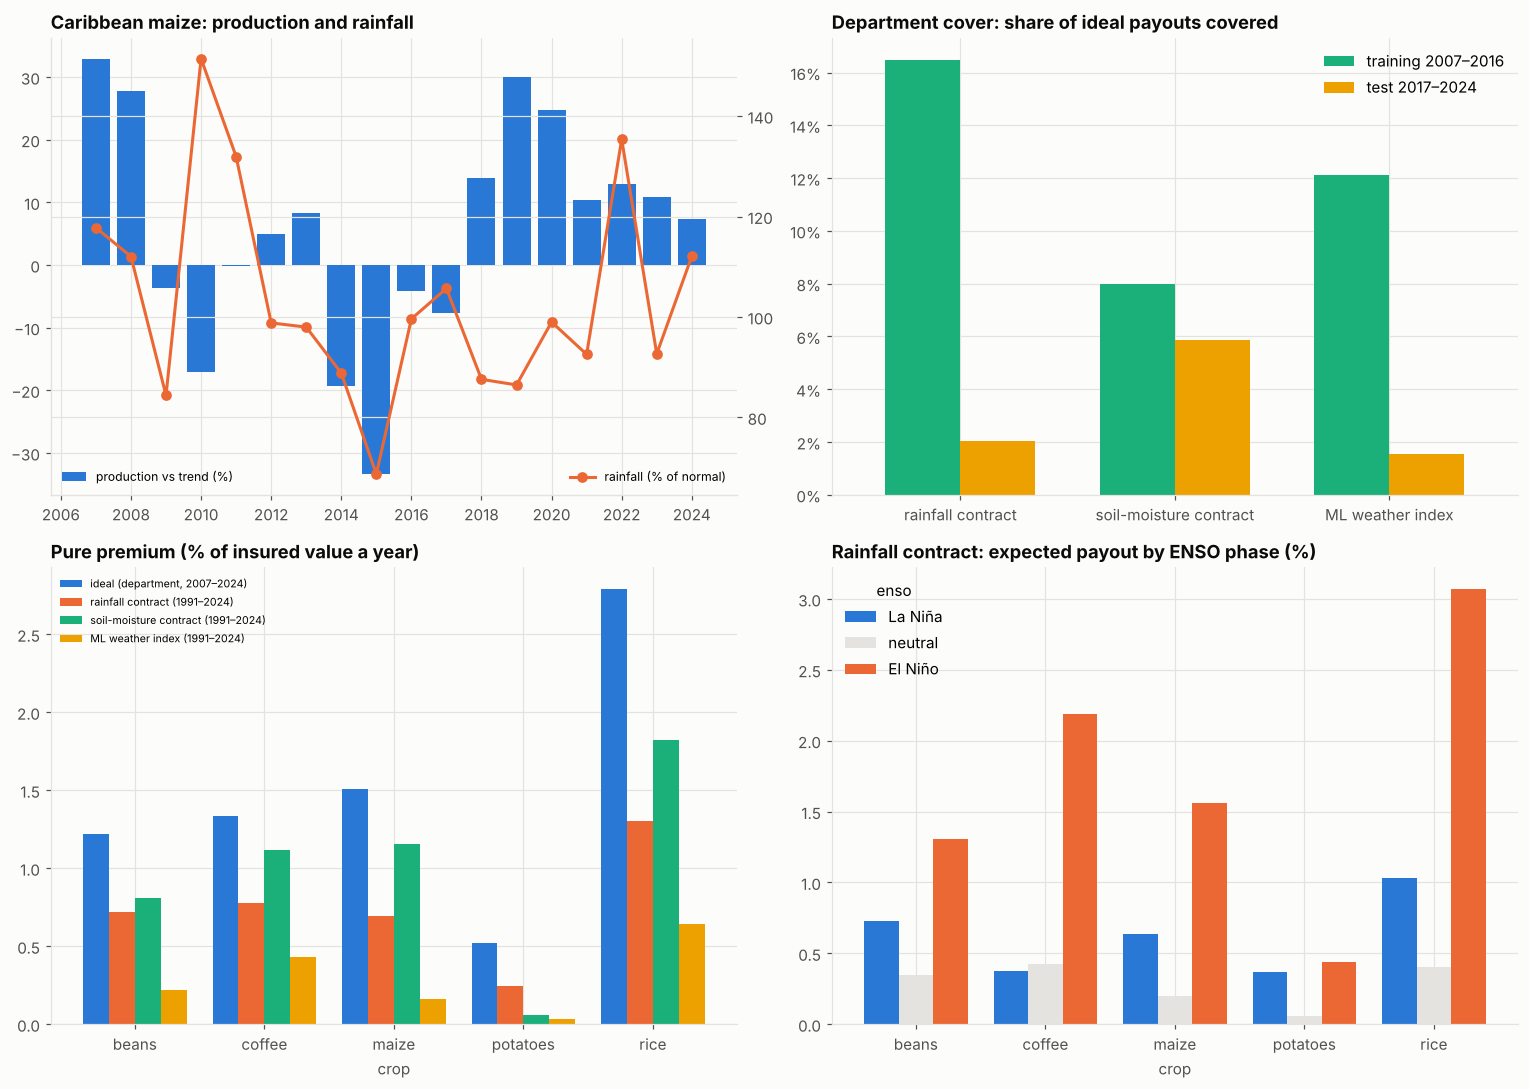

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
cm = CARIBBEAN_MAIZE
ax[0, 0].bar(
    cm.index,
    cm["production_vs_trend"] * 100,
    color=PALETTE[0],
    label="production vs trend (%)",
)
ax2 = ax[0, 0].twinx()
ax2.plot(
    cm.index,
    cm["rainfall_vs_normal"] * 100,
    "o-",
    color=PALETTE[1],
    label="rainfall (% of normal)",
)
ax[0, 0].set_title("Caribbean maize: production and rainfall")
ax[0, 0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax[0, 0].legend(loc="lower left", fontsize=8)
ax2.legend(loc="lower right", fontsize=8)

b = BASIS["covered share of ideal payouts"].unstack(0)
b.plot.bar(ax=ax[0, 1], color=[PALETTE[2], PALETTE[3]], width=0.7)
ax[0, 1].set_title("Department cover: share of ideal payouts covered")
ax[0, 1].tick_params(axis="x", rotation=0)
ax[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

PRICE.mul(100).plot.bar(ax=ax[1, 0], color=PALETTE[:4], width=0.8)
ax[1, 0].set_title("Pure premium (% of insured value a year)")
ax[1, 0].tick_params(axis="x", rotation=0)
ax[1, 0].legend(fontsize=7)

e = ENSO["rainfall contract"][["La Niña", "neutral", "El Niño"]] * 100
e.plot.bar(ax=ax[1, 1], color=[PALETTE[0], GRID, PALETTE[1]], width=0.8)
ax[1, 1].set_title("Rainfall contract: expected payout by ENSO phase (%)")
ax[1, 1].tick_params(axis="x", rotation=0)
fig.tight_layout()
save_fig(fig, "01_index_insurance")
plt.show()

In [15]:
mun_loss = (
    DATA.groupby("mun")
    .agg(
        lat=("lat", "first"),
        lon=("lon", "first"),
        name=("name", "first"),
        ideal=("ideal", "mean"),
    )
    .reset_index()
)
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Mean municipal ideal payout, 2007–2024",
        "Rank correlation with production: municipality vs department",
        "From department to farm: covered share of municipal losses",
        "Expected payout by ENSO phase, ML index (%)",
    ),
)
dash.add_trace(
    go.Scatter(
        x=mun_loss["lon"],
        y=mun_loss["lat"],
        mode="markers",
        text=mun_loss["name"],
        marker=dict(
            size=6, color=mun_loss["ideal"], colorscale="Reds", showscale=False
        ),
        showlegend=False,
    ),
    1,
    1,
)
for lvl_, col in zip(["municipality", "department"], PALETTE):
    dash.add_trace(
        go.Bar(
            x=SIGNAL.index,
            y=SIGNAL[lvl_].mean(axis=1),
            name=f"{lvl_} (mean over crops)",
            marker_color=col,
        ),
        1,
        2,
    )
dash.add_trace(
    go.Bar(
        x=FARM.index,
        y=FARM["covered share of municipal ideal payouts"],
        marker_color=PALETTE[3],
        showlegend=False,
    ),
    2,
    1,
)
en = ENSO["ML weather index"]
for ph, col in zip(
    ["La Niña", "neutral", "El Niño"], [PALETTE[0], GRID, PALETTE[1]]
):
    dash.add_trace(
        go.Bar(x=en.index, y=en[ph] * 100, name=ph, marker_color=col), 2, 2
    )
dash.update_layout(
    height=950,
    width=1450,
    template="simple_white",
    title="Index insurance for Colombian farmers",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**The weather signal in Colombia's municipal statistics is weak.** Across 1,087 municipalities and 73,092 crop-season observations, the rank correlation between production against trend and any weather feature is between −0.2 and +0.2, and close to zero for maize, beans, potatoes and rice. Adding municipalities up to departments sharpens it only for coffee (soil moisture −0.34, maximum-temperature anomaly +0.36, ENSO +0.19: warmer, drier seasons go with better coffee harvests relative to trend) and a little for rice. The clearest single episode is in the data: Caribbean maize fell 33% below trend in the 2015 El Niño, with rainfall at 69% of normal, and 17% below in the 2010 La Niña floods. But these are a few years among eighteen, and many other dry or wet seasons left no mark on production.

**Why the signal is weak is partly the data.** About one municipal yield in five repeats the previous year's figure exactly, a sign that it was carried forward rather than measured, and the year-to-year changes in the national yields implied by the municipal panel move *against* FAOSTAT's series for maize (correlation −0.18) and beans (−0.35). A weather index can only be as good as the losses it is checked against; here the losses themselves are noisy. Irrigation (rice, much of the potato crop) and the diversity of altitudes within a department also weaken the link.

**No trigger survives out of sample.** On 2007–2016 the rainfall contract covers 16% of the department's ideal payouts and the machine-learning index 12%; on 2017–2024 both cover about 2% and the soil-moisture contract 6%, while 85–96% of the loss events receive nothing and 86–95% of the money paid goes to seasons without a loss. The machine-learning index has an out-of-fold R² of 0.05 in training and a negative R² in the test years; its largest gains come from ENSO, latitude and soil moisture, which is the department-level signal found above, but it is too weak to time payouts. This is the basis-risk problem the index-insurance literature describes, measured: a contract that pays mostly in the wrong seasons is worth less to a farmer than its price.

**Department covers do not reach the farm.** Even a perfect department area-yield cover would pay only 6% of what the municipalities' own shortfalls call for, and 87% of the municipal loss events would receive nothing: the dispersion of municipal losses within a department is 2.5 times their average. Losses in Colombia are local, which favours municipal area-yield covers, or index covers built on much finer data, over department-wide triggers.

**ENSO moves the price.** Over 34 years of weather, the rainfall contract pays on average 0.2–1.3% of insured value a year depending on the crop, but four to eight times as much in El Niño seasons as in neutral ones (rice 3.1% against 0.4%, coffee 2.2% against 0.4%); the soil-moisture contract pays most in La Niña. With the ONI at +2.16 in July–September 2026, an insurer selling the rainfall contract for 2027 at its long-run price would be charging about half its expected cost or less. The realised department losses do not follow the contracts: El Niño raised the losses of beans and maize (2.1% against about 1.2% in neutral years) but not those of coffee and rice, so the higher expected payout is mostly basis risk the insurer would be paid for.

**Limitations.** Production statistics are survey estimates with known gaps; trends are fitted on the whole series, which uses future data for the department units; the weather data are gridded estimates (CHIRPS at about 5 km, NASA POWER at about 50 km) averaged over municipalities rather than measured on farms; the contracts are priced with a 50% load and no reinsurance or capital cost; and the machine-learning index is calibrated on only ten years of department data.

In [16]:
QUALITY.to_csv(OUT_DIR / "data_quality_by_crop.csv")
LOSS_SUMMARY.to_csv(OUT_DIR / "loss_frequency_by_crop.csv")
SIGNAL.to_csv(OUT_DIR / "weather_signal_municipality_vs_department.csv")
CARIBBEAN_MAIZE.to_csv(OUT_DIR / "caribbean_maize_by_year.csv")
ML_SCORES.to_csv(OUT_DIR / "ml_index_scores.csv")
BASIS.to_csv(OUT_DIR / "basis_risk_department.csv")
BASIS_CROP.to_csv(OUT_DIR / "basis_risk_by_crop.csv")
FARM.to_csv(OUT_DIR / "department_cover_at_municipal_level.csv")
PRICE.to_csv(OUT_DIR / "pure_premium_by_crop.csv")
ENSO.to_csv(OUT_DIR / "expected_payout_by_enso_phase.csv")
FAO_CHECK.to_csv(OUT_DIR / "faostat_cross_check.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_index_insurance.png, basis_risk_by_crop.csv, basis_risk_department.csv, caribbean_maize_by_year.csv, dashboard.html, dashboard.png, data_quality_by_crop.csv, department_cover_at_municipal_level.csv, expected_payout_by_enso_phase.csv, faostat_cross_check.csv, loss_frequency_by_crop.csv, ml_index_scores.csv, pure_premium_by_crop.csv, weather_signal_municipality_vs_department.csv


## References

### Finance and regulation

- Miranda, M. J., & Farrin, K. (2012). Index insurance for developing countries. *Applied Economic Perspectives and Policy, 34*(3), 391–427. https://doi.org/10.1093/aepp/pps031
- Carter, M., de Janvry, A., Sadoulet, E., & Sarris, A. (2017). Index insurance for developing country agriculture: A reassessment. *Annual Review of Resource Economics, 9*, 421–438. https://doi.org/10.1146/annurev-resource-100516-053352
- Clarke, D. J. (2016). A theory of rational demand for index insurance. *American Economic Journal: Microeconomics, 8*(1), 283–306. https://doi.org/10.1257/mic.20140103
- Jensen, N. D., Barrett, C. B., & Mude, A. G. (2016). Index insurance quality and basis risk: Evidence from northern Kenya. *American Journal of Agricultural Economics, 98*(5), 1450–1469. https://doi.org/10.1093/ajae/aaw046
- Funk, C., Peterson, P., Landsfeld, M., Pedreros, D., Verdin, J., Shukla, S., Husak, G., Rowland, J., Harrison, L., Hoell, A., & Michaelsen, J. (2015). The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes. *Scientific Data, 2*, 150066. https://doi.org/10.1038/sdata.2015.66
- Gelaro, R., McCarty, W., Suárez, M. J., Todling, R., Molod, A., Takacs, L., Randles, C. A., Darmenov, A., Bosilovich, M. G., Reichle, R., et al. (2017). The Modern-Era Retrospective Analysis for Research and Applications, Version 2 (MERRA-2). *Journal of Climate, 30*(14), 5419–5454. https://doi.org/10.1175/JCLI-D-16-0758.1

### Machine learning and deep learning

- Biffis, E., & Chavez, E. (2017). Satellite data and machine learning for weather risk management and food security. *Risk Analysis, 37*(8), 1508–1521. https://doi.org/10.1111/risa.12847
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html